# EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from tqdm import tqdm
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error
import os
import pickle
import time
from IPython import get_ipython
from IPython.display import display, clear_output
import ipywidgets as widgets
import sys
from statsmodels.graphics.tsaplots import plot_acf

# Analysis parameters
config = {
    # Financial parameters
    'risk_free_rate': 2.7,  # Current risk-free rate (%)

    # Lease parameters
    'max_lease': 99,  # Maximum HDB lease in years
    'min_acceptable_lease': 35,  # Minimum lease considered good for resale

    # ROI score parameters
    'cagr_weight': 0.7,  # Weight for CAGR in ROI calculation
    'sharpe_weight': 0.2,  # Weight for Sharpe ratio in ROI calculation
    'lease_weight': 0.1,  # Weight for remaining lease in ROI calculation
    'sharpe_scaling_factor': 10,  # Scaling factor for Sharpe ratio
    'lease_scaling_factor': 25,  # Scaling factor for lease factor

    # ARIMA parameters
    'forecast_years': 10,  # Years to forecast into future
    'min_years_required': 10,  # Minimum years of data for ARIMA
    'max_reasonable_cagr': 10,  # Cap for CAGR predictions (%)
    'max_reasonable_price_multiplier': 3, # Multiplier for cap on reasonable price
    'validation_size': 0.2,  # Proportion of data for validation
    'mape_threshold': 30,  # Maximum acceptable MAPE (%)


    # Filtering parameters
    'recent_years_threshold': 2,  # Recent data threshold for towns

    # File paths
    'checkpoint_dir': 'checkpoints',
    'arima_models_file': 'checkpoints/arima_models.pkl',
    'predictions_file': 'checkpoints/arima_predictions.csv',
    'validation_file': 'checkpoints/arima_validation.csv'
}

# Load the datasets
df_1990_1999 = pd.read_csv("data/Resale Flat Prices (Based on Approval Date), 1990 - 1999.csv")
df_2000_2012 = pd.read_csv("data/Resale Flat Prices (Based on Approval Date), 2000 - Feb 2012.csv")
df_2012_2014 = pd.read_csv("data/Resale Flat Prices (Based on Registration Date), From Mar 2012 to Dec 2014.csv")
df_2015_2016 = pd.read_csv("data/Resale Flat Prices (Based on Registration Date), From Jan 2015 to Dec 2016.csv")
df_2017_onwards = pd.read_csv("data/Resale flat prices based on registration date from Jan-2017 onwards.csv")

# Combine all datasets
df_all = pd.concat([df_1990_1999, df_2000_2012, df_2012_2014, df_2015_2016, df_2017_onwards], ignore_index=True)

# Convert date columns to datetime format
df_all['approval_date'] = pd.to_datetime(df_all['month'], format='%Y-%m')

# Add a year column for easier analysis
df_all['year'] = df_all['approval_date'].dt.year

print(df_all.head())

     month        town flat_type block       street_name storey_range  \
0  1990-01  ANG MO KIO    1 ROOM   309  ANG MO KIO AVE 1     10 TO 12   
1  1990-01  ANG MO KIO    1 ROOM   309  ANG MO KIO AVE 1     04 TO 06   
2  1990-01  ANG MO KIO    1 ROOM   309  ANG MO KIO AVE 1     10 TO 12   
3  1990-01  ANG MO KIO    1 ROOM   309  ANG MO KIO AVE 1     07 TO 09   
4  1990-01  ANG MO KIO    3 ROOM   216  ANG MO KIO AVE 1     04 TO 06   

   floor_area_sqm      flat_model  lease_commence_date  resale_price  \
0            31.0        IMPROVED                 1977        9000.0   
1            31.0        IMPROVED                 1977        6000.0   
2            31.0        IMPROVED                 1977        8000.0   
3            31.0        IMPROVED                 1977        6000.0   
4            73.0  NEW GENERATION                 1976       47200.0   

  remaining_lease approval_date  year  
0             NaN    1990-01-01  1990  
1             NaN    1990-01-01  1990  
2       

In [2]:
df_all.describe()

,floor_area_sqm,lease_commence_date,resale_price,approval_date,year
count,947370.000000,947370.000000,9.473700e+05,947370,947370.000000
mean,95.680227,1988.486893,3.273270e+05,2007-01-06 17:01:04.318693,2006.553339
min,28.000000,1966.000000,5.000000e+03,1990-01-01 00:00:00,1990.000000
25%,73.000000,1981.000000,1.950000e+05,1999-02-01 00:00:00,1999.000000
50%,93.000000,1986.000000,3.000000e+05,2005-08-01 00:00:00,2005.000000
75%,113.000000,1996.000000,4.250000e+05,2015-02-01 00:00:00,2015.000000
max,366.700000,2021.000000,1.600000e+06,2025-02-01 00:00:00,2025.000000
std,25.787784,10.873668,1.766560e+05,NaN,9.582218


In [3]:
df_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 947370 entries, 0 to 947369
Data columns (total 13 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   month                947370 non-null  str           
 1   town                 947370 non-null  str           
 2   flat_type            947370 non-null  str           
 3   block                947370 non-null  str           
 4   street_name          947370 non-null  str           
 5   storey_range         947370 non-null  str           
 6   floor_area_sqm       947370 non-null  float64       
 7   flat_model           947370 non-null  str           
 8   lease_commence_date  947370 non-null  int64         
 9   resale_price         947370 non-null  float64       
 10  remaining_lease      238320 non-null  object        
 11  approval_date        947370 non-null  datetime64[us]
 12  year                 947370 non-null  int32         
dtypes: datetime64[us](1), flo

In [4]:
df_all.isnull().sum()

month                       0
town                        0
flat_type                   0
block                       0
street_name                 0
storey_range                0
floor_area_sqm              0
flat_model                  0
lease_commence_date         0
resale_price                0
remaining_lease        709050
approval_date               0
year                        0
dtype: int64

In [5]:
# Find the latest year in the dataset
latest_year = df_all['year'].max()
print(f"\nLatest year in dataset: {latest_year}")

# Find the latest date in the dataset
latest_date = df_all['approval_date'].max()
print(f"\nLatest date in dataset: {latest_date}")

# Add a price per square meter column
df_all['price_per_sqm'] = df_all['resale_price'] / df_all['floor_area_sqm']

# Get the data range for each town
town_data_range = df_all.groupby('town')['year'].agg(['min', 'max']).reset_index()
print("\nYear range for each town:")
print(town_data_range.head())

# Identify towns that don't have data in recent years
# Let's consider towns that don't have data in the last config['recent_years_threshold'] years as invalid
threshold_year = latest_year - config['recent_years_threshold']
towns_without_recent_data = town_data_range[town_data_range['max'] < threshold_year]['town'].tolist()

print(f"\nTowns without data in the last {config['recent_years_threshold']} years (before {threshold_year}):")
print(towns_without_recent_data)

# Filter out these towns from the analysis
df_filtered = df_all[~df_all['town'].isin(towns_without_recent_data)].copy()

# Since HDB flat leases are 99 years, we can replace all NaN values in remaining_lease
current_year = df_filtered['year'].max()
df_filtered['flat_age'] = current_year - df_filtered['lease_commence_date']
df_filtered['remaining_lease'] = config['max_lease'] - df_filtered['flat_age']

print(f"\nOriginal dataset shape: {df_all.shape}")
print(f"Filtered dataset shape: {df_filtered.shape}")

# Calculate average prices by town and year for the filtered dataset
town_year_prices = df_filtered.groupby(['town', 'year'])['price_per_sqm'].mean().reset_index()

# Calculate average remaining lease for each town
town_remaining_lease = df_filtered.groupby('town')['remaining_lease'].mean().reset_index()
town_remaining_lease.rename(columns={'remaining_lease': 'avg_remaining_lease'}, inplace=True)

# Define risk-free rate - this needs to be defined before the Sharpe ratio calculation
risk_free_rate = config['risk_free_rate']


Latest year in dataset: 2025

Latest date in dataset: 2025-02-01 00:00:00

Year range for each town:
          town   min   max
0   ANG MO KIO  1990  2025
1        BEDOK  1990  2025
2       BISHAN  1990  2025
3  BUKIT BATOK  1990  2025
4  BUKIT MERAH  1990  2025

Towns without data in the last 2 years (before 2023):
['LIM CHU KANG']

Original dataset shape: (947370, 14)
Filtered dataset shape: (947306, 15)


In [6]:
# Calculate price appreciation rates for each town
appreciation_rates = []
for town in town_year_prices['town'].unique():
    town_data = town_year_prices[town_year_prices['town'] == town].sort_values('year')

    if len(town_data) > 1:
        # Calculate year-over-year appreciation rates
        town_data['prev_price'] = town_data['price_per_sqm'].shift(1)
        town_data['yoy_appreciation'] = (town_data['price_per_sqm'] - town_data['prev_price']) / town_data['prev_price'] * 100

        # Calculate compound annual growth rate (CAGR)
        earliest_year = town_data['year'].min()
        latest_year = town_data['year'].max()
        earliest_price = town_data[town_data['year'] == earliest_year]['price_per_sqm'].values[0]
        latest_price = town_data[town_data['year'] == latest_year]['price_per_sqm'].values[0]
        years_diff = latest_year - earliest_year

        if years_diff > 0:
            cagr = (((latest_price / earliest_price) ** (1 / years_diff)) - 1) * 100
        else:
            cagr = 0

        # Calculate average annual appreciation rate
        avg_annual_appreciation = town_data['yoy_appreciation'].mean()

        # Calculate volatility (standard deviation of annual returns)
        volatility = town_data['yoy_appreciation'].std()

        # Calculate rolling window Sharpe ratio (if enough data points)
        rolling_sharpe_ratios = []
        if len(town_data) >= 5:  # Need at least 5 years of data for a meaningful rolling window
            window_size = min(5, len(town_data) - 1)  # Use 5-year window or less if not enough data
            for i in range(len(town_data) - window_size):
                window_data = town_data.iloc[i:i+window_size+1]
                window_returns = window_data['yoy_appreciation'].dropna()
                if len(window_returns) > 1:  # Need at least 2 points to calculate std
                    window_mean = window_returns.mean()
                    window_std = window_returns.std()
                    if window_std > 0:  # Avoid division by zero
                        window_sharpe = (window_mean - risk_free_rate) / window_std
                        rolling_sharpe_ratios.append(window_sharpe)

        # Use rolling Sharpe ratio average if available, otherwise use the traditional Sharpe ratio
        if rolling_sharpe_ratios:
            rolling_sharpe = np.mean(rolling_sharpe_ratios)
        else:
            # Fall back to traditional Sharpe ratio if not enough data points
            rolling_sharpe = (avg_annual_appreciation - risk_free_rate) / volatility if volatility > 0 else 0

        appreciation_rates.append({
            'town': town,
            'cagr': cagr,
            'avg_annual_appreciation': avg_annual_appreciation,
            'volatility': volatility,
            'rolling_sharpe': rolling_sharpe,
            'earliest_year': earliest_year,
            'latest_year': latest_year,
            'earliest_price': earliest_price,
            'latest_price': latest_price
        })

appreciation_df = pd.DataFrame(appreciation_rates)

# Merge with remaining lease data
appreciation_df = pd.merge(appreciation_df, town_remaining_lease, on='town', how='left')

# Calculate remaining lease factor (normalized between 0 and 1)
# Properties with longer remaining leases get scores closer to 1
appreciation_df['lease_factor'] = (appreciation_df['avg_remaining_lease'] - config['min_acceptable_lease']) / (config['max_lease'] - config['min_acceptable_lease'])
appreciation_df['lease_factor'] = appreciation_df['lease_factor'].clip(0, 1)  # Ensure values are between 0 and 1

print("\nAppreciation rates for towns with recent data:")
print(appreciation_df.head())


Appreciation rates for towns with recent data:
          town      cagr  avg_annual_appreciation  volatility  rolling_sharpe  \
0   ANG MO KIO  6.629075                 7.487638   14.488580        0.221982   
1        BEDOK  6.408484                 7.138215   13.146998        0.226114   
2       BISHAN  6.187528                 6.780449   11.748302        0.237818   
3  BUKIT BATOK  6.019132                 6.710779   12.752657        0.062443   
4  BUKIT MERAH  7.033637                 7.668035   12.279177        0.336776   

   earliest_year  latest_year  earliest_price  latest_price  \
0           1990         2025      718.054554   6788.985426   
1           1990         2025      762.953367   6709.142445   
2           1990         2025      964.231846   7884.140667   
3           1990         2025      838.405355   6484.889050   
4           1990         2025      804.267950   8681.816970   

   avg_remaining_lease  lease_factor  
0            55.076346      0.313693  
1       

In [7]:
# Sort towns by CAGR to find the best performing towns
top_towns = appreciation_df.sort_values('cagr', ascending=False).head(10)
print("\nTop 10 towns by CAGR historically:")
print(top_towns[['town', 'cagr', 'earliest_year', 'latest_year']])

# Calculate Risk-Adjusted Return (Sharpe Ratio) using appreciation rate and volatility
# The risk-free rate represents the interest an investor would expect from an absolutely risk-free investment over a specified period of time
# Since SGS bond yields are currently about 2.7% at time of writing, we will assume the risk free rate is 2.7%

# We now use the rolling_sharpe calculated earlier instead of calculating it here

# Calculate typical range of Sharpe ratios to determine appropriate scaling
sharpe_min = appreciation_df['rolling_sharpe'].min()
sharpe_max = appreciation_df['rolling_sharpe'].max()
sharpe_median = appreciation_df['rolling_sharpe'].median()
print(f"\nSharpe Ratio stats - Min: {sharpe_min:.4f}, Max: {sharpe_max:.4f}, Median: {sharpe_median:.4f}")

# Apply scaling factor to Sharpe ratio to make its contribution more proportional to its weight
sharpe_scaling_factor = config['sharpe_scaling_factor']

# Calculate ROI score with lease factor and scaled Sharpe ratio
# We are giving CAGR a higher weightage because our goal is to resell the HDB flat
appreciation_df['roi_score'] = (
    config['cagr_weight'] * appreciation_df['cagr'] +
    config['sharpe_weight'] * appreciation_df['rolling_sharpe'] * sharpe_scaling_factor +  # Apply scaling to the Sharpe ratio
    config['lease_weight'] * appreciation_df['lease_factor'] * config['lease_scaling_factor']  # Scaled to maintain a balanced contribution
)

# ROI Score Component Explanation:
# 1. CAGR (70% weight): Measures the compound annual growth rate of price per sqm over the entire period.
#    This is the primary factor since it represents overall historical price appreciation.
#
# 2. Rolling Sharpe Ratio (20% weight): Measures risk-adjusted return using 5-year rolling windows.
#    This considers the consistency and volatility of returns, giving higher scores to towns with
#    steady price growth and lower volatility. Scaled by a factor of 10 to make its contribution
#    proportional to its intended weight.
#
# 3. Lease Factor (10% weight): Accounts for the impact of remaining lease years on future resale value.
#    Normalized between 0-1 based on remaining years (35-99 years), then scaled by 25 to ensure its contribution
#    is proportional to its intended weight. Towns with longer remaining leases score higher.
#
# The scaling factors ensure that each component contributes proportionally to the ROI score
# according to its intended weight, preventing any single factor from having an oversized impact.


Top 10 towns by CAGR historically:
               town      cagr  earliest_year  latest_year
19        SEMBAWANG  9.030490           1990         2025
18       QUEENSTOWN  8.343268           1990         2025
20         SENGKANG  7.593430           1990         2025
23        TOA PAYOH  7.465640           1990         2025
24        WOODLANDS  7.111877           1990         2025
6       BUKIT TIMAH  7.034793           1990         2025
4       BUKIT MERAH  7.033637           1990         2025
7      CENTRAL AREA  7.033419           1990         2025
9          CLEMENTI  6.700160           1990         2025
14  KALLANG/WHAMPOA  6.689792           1990         2025

Sharpe Ratio stats - Min: -0.0083, Max: 0.4849, Median: 0.2313


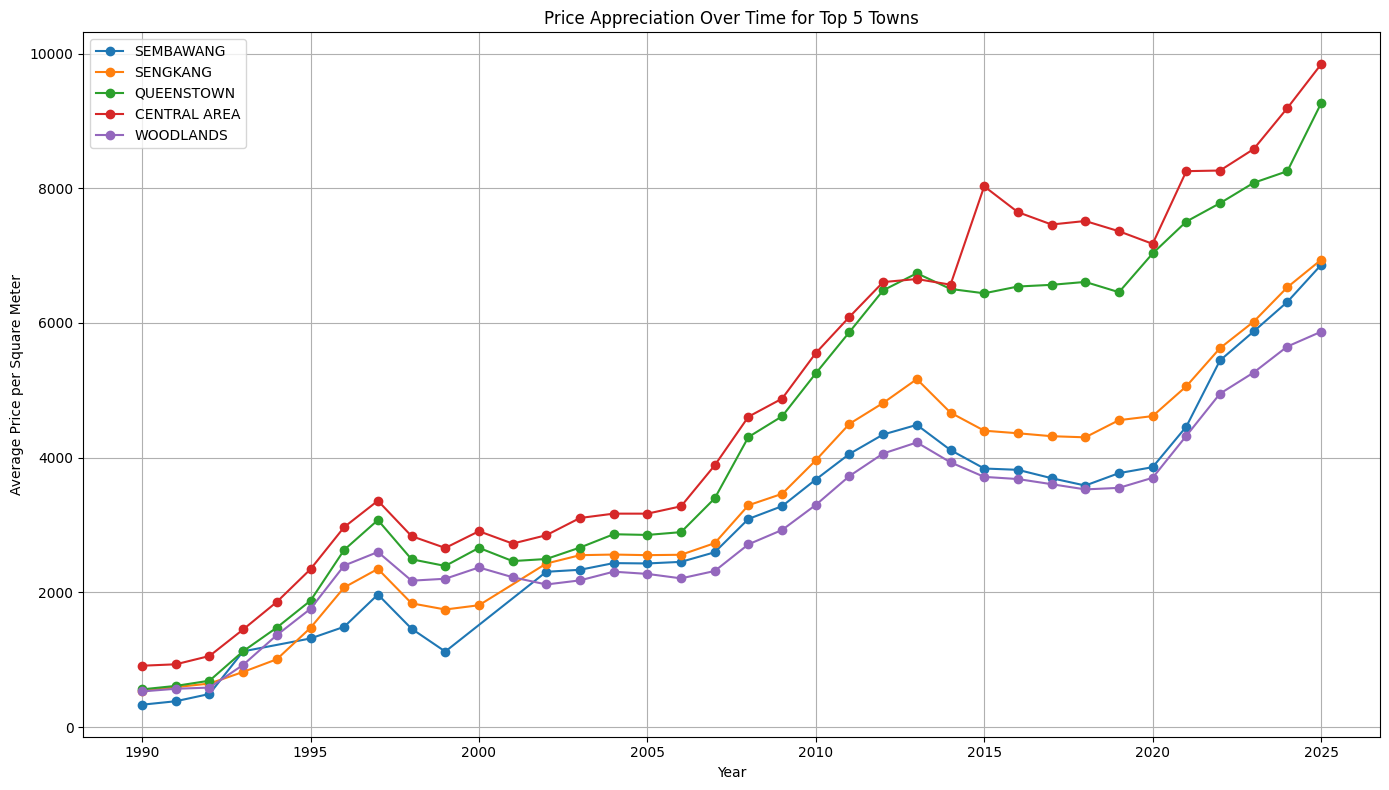

In [8]:
# Rank towns by ROI score
top_roi_locations = appreciation_df.sort_values('roi_score', ascending=False).reset_index(drop=True)

# Plot historical price appreciation over time for top 5 towns
top_5_towns = top_roi_locations['town'].head(5).tolist()
plt.figure(figsize=(14, 8))

for town in top_5_towns:
    town_data = town_year_prices[town_year_prices['town'] == town]
    plt.plot(town_data['year'], town_data['price_per_sqm'], marker='o', label=town)

plt.title('Price Appreciation Over Time for Top 5 Towns')
plt.xlabel('Year')
plt.ylabel('Average Price per Square Meter')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

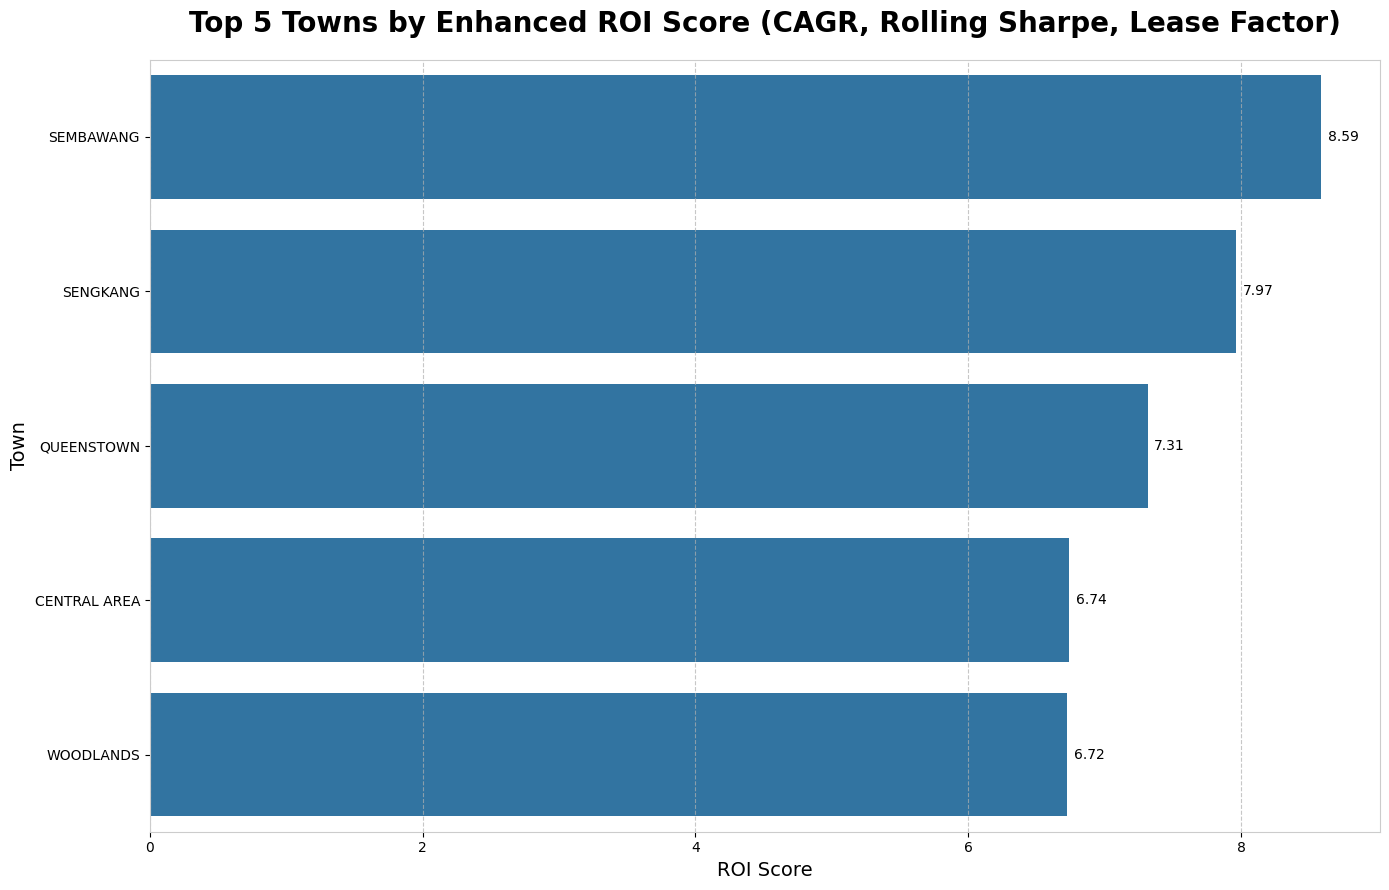

In [9]:
# Plot top 5 towns by ROI score
plt.figure(figsize=(14, 9))

# Create horizontal bar plot with improved styling
ax = sns.barplot(x='roi_score', y='town', data=top_roi_locations.head(5))

# Add data labels to the bars
for i, v in enumerate(top_roi_locations.head(5)['roi_score']):
    ax.text(v + 0.05, i, f"{v:.2f}", va='center')

# Improve title and labels with better formatting
plt.title('Top 5 Towns by Enhanced ROI Score (CAGR, Rolling Sharpe, Lease Factor)', fontsize=20, fontweight='bold', pad=20)
plt.xlabel('ROI Score', fontsize=14)
plt.ylabel('Town', fontsize=14)

# Add a subtle grid for better readability
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Add a border around the plot
for spine in ax.spines.values():
    spine.set_color('#cccccc')
    spine.set_linewidth(0.8)

plt.tight_layout()
plt.show()

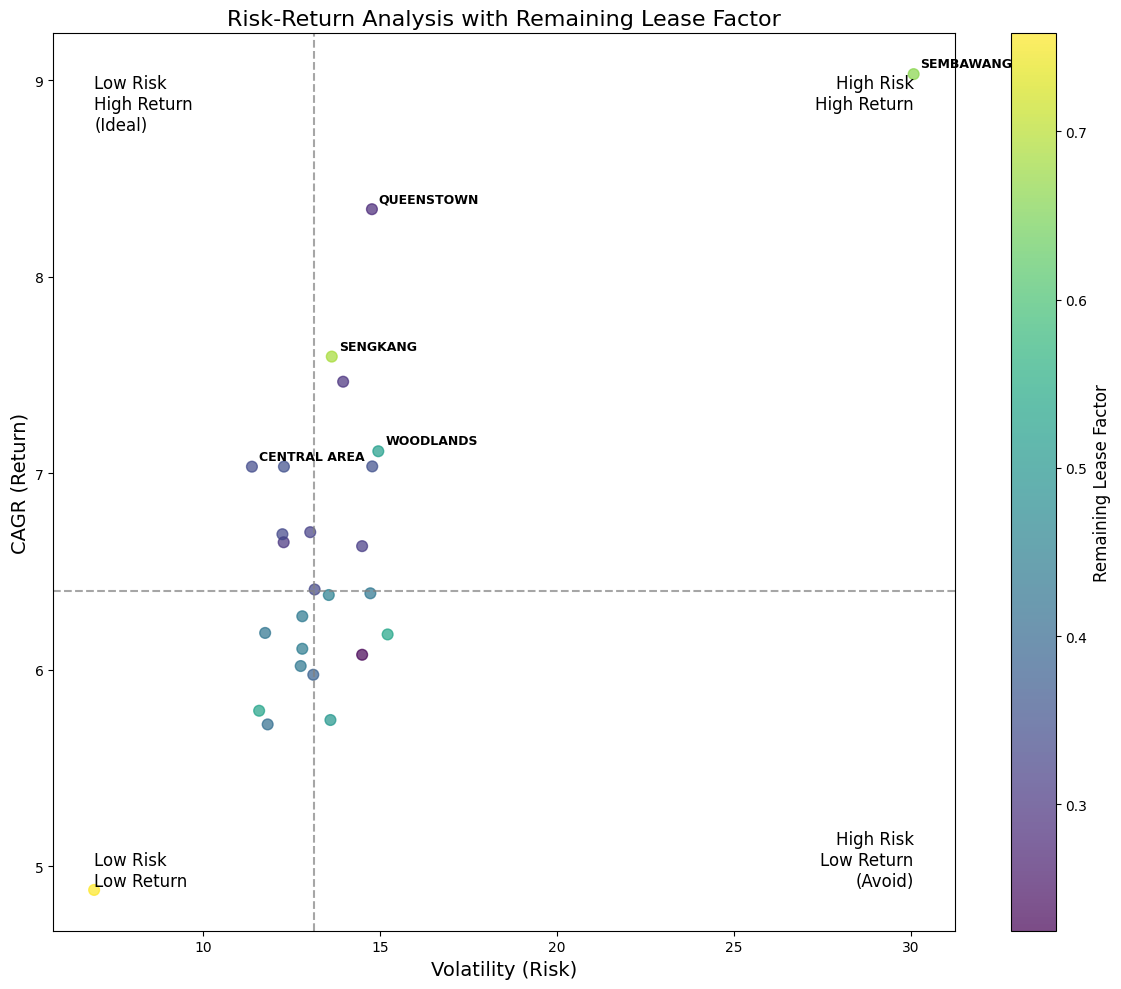


Top 5 Towns by ROI Score:
           town      cagr  rolling_sharpe  lease_factor  roi_score
0     SEMBAWANG  9.030490        0.308834      0.660324   8.589821
1      SENGKANG  7.593430        0.468157      0.685363   7.965122
2    QUEENSTOWN  8.343268        0.383523      0.282980   7.314784
3  CENTRAL AREA  7.033419        0.484874      0.339786   6.742607
4     WOODLANDS  7.111877        0.223696      0.518961   6.723110


In [10]:
# Create a quadrant analysis plot
plt.figure(figsize=(12, 10))

# Calculate median values to create quadrants
median_volatility = appreciation_df['volatility'].median()
median_cagr = appreciation_df['cagr'].median()

# Create a colormap based on the remaining lease factor
scatter = plt.scatter(appreciation_df['volatility'], appreciation_df['cagr'],
                     alpha=0.7, c=appreciation_df['lease_factor'], s=60,
                     cmap='viridis')

# Add a colorbar to show the lease factor
cbar = plt.colorbar(scatter)
cbar.set_label('Remaining Lease Factor', fontsize=12)

# Add quadrant lines
plt.axvline(x=median_volatility, color='gray', linestyle='--', alpha=0.7)
plt.axhline(y=median_cagr, color='gray', linestyle='--', alpha=0.7)

# Add labels for top 5 towns by ROI score
for idx, row in top_roi_locations.head(5).iterrows():
    plt.annotate(row['town'],
                 xy=(row['volatility'], row['cagr']),
                 xytext=(5, 5),
                 textcoords='offset points',
                 fontsize=9,
                 fontweight='bold')

# Add quadrant labels
plt.text(appreciation_df['volatility'].min(), appreciation_df['cagr'].max(),
         'Low Risk\nHigh Return\n(Ideal)', fontsize=12, ha='left', va='top')
plt.text(appreciation_df['volatility'].max(), appreciation_df['cagr'].max(),
         'High Risk\nHigh Return', fontsize=12, ha='right', va='top')
plt.text(appreciation_df['volatility'].min(), appreciation_df['cagr'].min(),
         'Low Risk\nLow Return', fontsize=12, ha='left', va='bottom')
plt.text(appreciation_df['volatility'].max(), appreciation_df['cagr'].min(),
         'High Risk\nLow Return\n(Avoid)', fontsize=12, ha='right', va='bottom')

plt.title('Risk-Return Analysis with Remaining Lease Factor', fontsize=16)
plt.xlabel('Volatility (Risk)', fontsize=14)
plt.ylabel('CAGR (Return)', fontsize=14)
plt.tight_layout()
plt.show()

print("\nTop 5 Towns by ROI Score:")
print(top_roi_locations.head()[['town', 'cagr', 'rolling_sharpe', 'lease_factor', 'roi_score']])


<Figure size 1000x500 with 0 Axes>

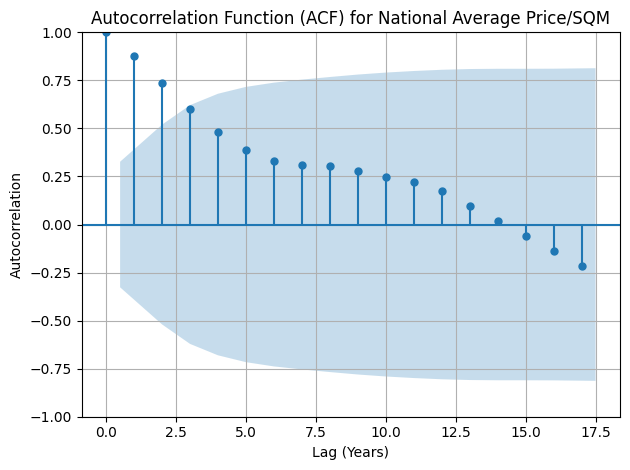


Generating ACF plots for Top 5 Towns by ROI Score...


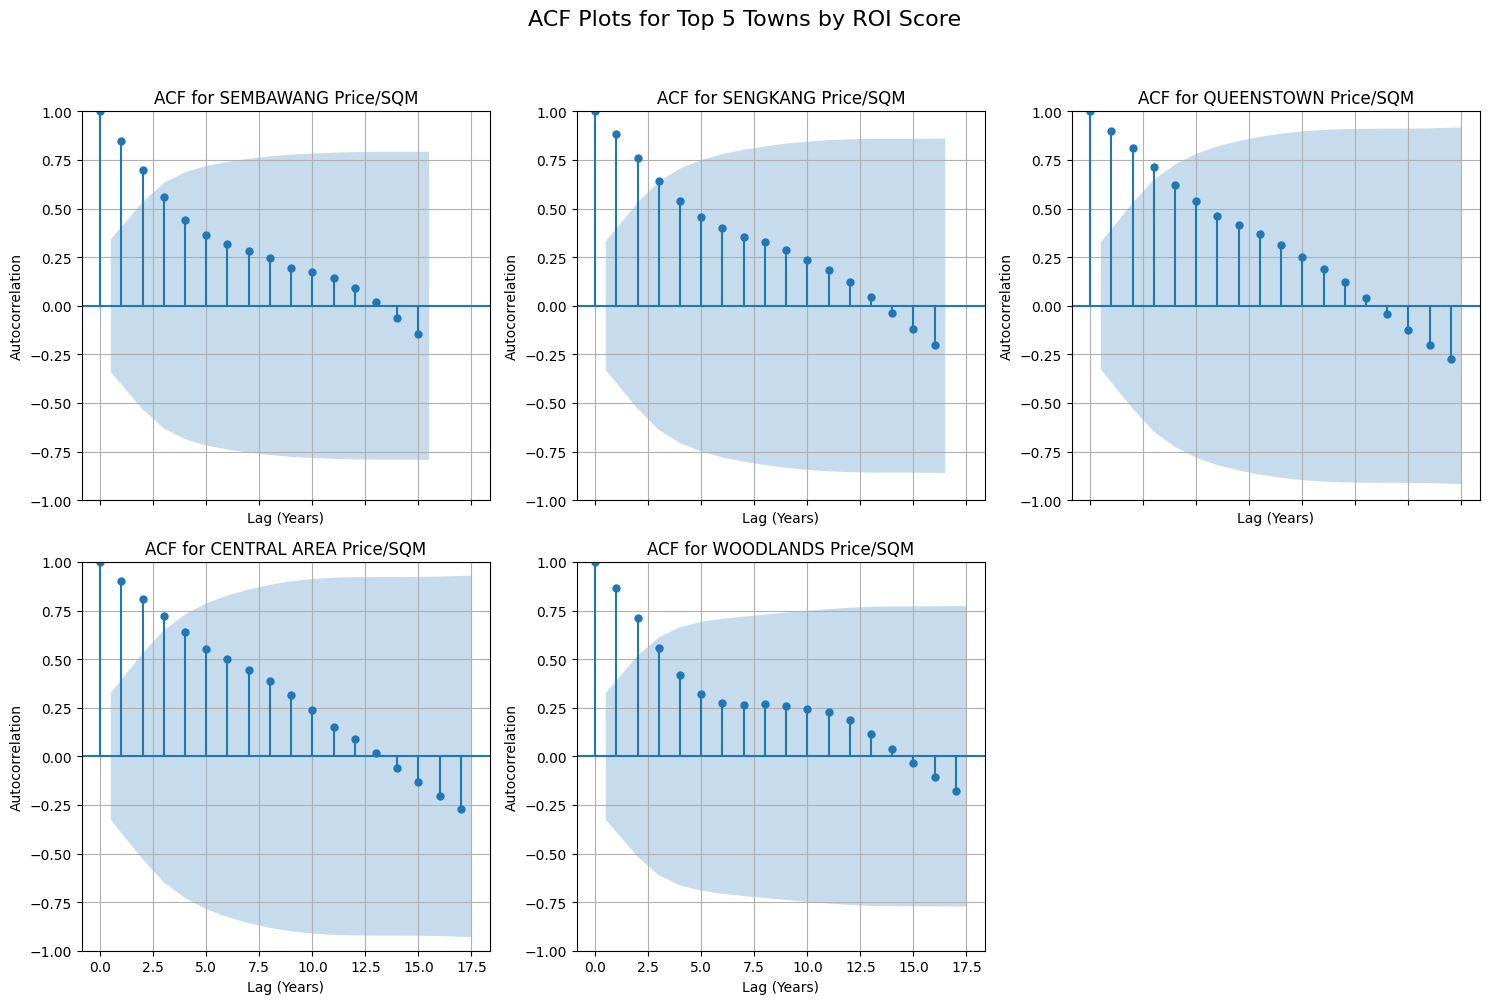

In [11]:
# Calculate national average price per sqm per year
national_avg_prices = df_filtered.groupby('year')['price_per_sqm'].mean()

# Plot ACF for National Average
plt.figure(figsize=(10, 5))
plot_acf(national_avg_prices, lags=min(20, len(national_avg_prices)//2 - 1), title='Autocorrelation Function (ACF) for National Average Price/SQM')
plt.xlabel('Lag (Years)')
plt.ylabel('Autocorrelation')
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot ACF for Top 5 Towns by ROI
print("\nGenerating ACF plots for Top 5 Towns by ROI Score...")
fig, axes = plt.subplots(2, 3, figsize=(15, 10), sharex=True) # Create figure and axes array
axes = axes.flatten() # Flatten the 2x3 array for easy iteration

for i, town in enumerate(top_5_towns):
    if i >= len(axes):
        break # Avoid index error if fewer than 6 axes needed

    ax = axes[i] # Select the appropriate axes
    town_data = town_year_prices[town_year_prices['town'] == town].set_index('year')['price_per_sqm']

    if len(town_data) > 3: # Need enough data points for meaningful ACF
        plot_acf(town_data, ax=ax, lags=min(20, len(town_data)//2 - 1), title=f'ACF for {town} Price/SQM')
        ax.set_xlabel('Lag (Years)') # Set labels on the specific axes
        ax.set_ylabel('Autocorrelation')
        ax.grid(True)
    else:
        print(f"Skipping ACF for {town}: Insufficient data points ({len(town_data)})")
        ax.set_title(f'{town} (Insufficient Data)') # Indicate missing data on the plot
        ax.axis('off') # Hide axes for skipped plots

# Hide any unused subplots (if fewer than 5 towns)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle('ACF Plots for Top 5 Towns by ROI Score', fontsize=16, y=1.0)
plt.tight_layout(rect=[0, 0, 1, 0.97]) # Adjust layout to prevent title overlap
plt.show()


1. ANALYSIS BY FLAT TYPE WITHIN TOP TOWNS
------------------------------------------

Flat Type Analysis for SEMBAWANG:
flat_type  avg_price_per_sqm  recent_transactions     cagr
   3 ROOM        6810.005052                  297 9.408338
   4 ROOM        5970.842895                 1474 5.075078
   5 ROOM        5443.598559                  824 4.006274
   2 ROOM        7659.814082                  242 3.188336
EXECUTIVE        5065.528617                  205 3.042491

Flat Type Analysis for SENGKANG:
flat_type  avg_price_per_sqm  recent_transactions     cagr
   3 ROOM        6857.430292                  514 8.213083
   4 ROOM        6209.506719                 3365 7.123386
   5 ROOM        5703.136562                 2263 3.896689
EXECUTIVE        5628.819267                  377 3.357989
   2 ROOM        7504.023976                  188 3.239135

Flat Type Analysis for QUEENSTOWN:
flat_type  avg_price_per_sqm  recent_transactions     cagr
   2 ROOM        7020.865898              

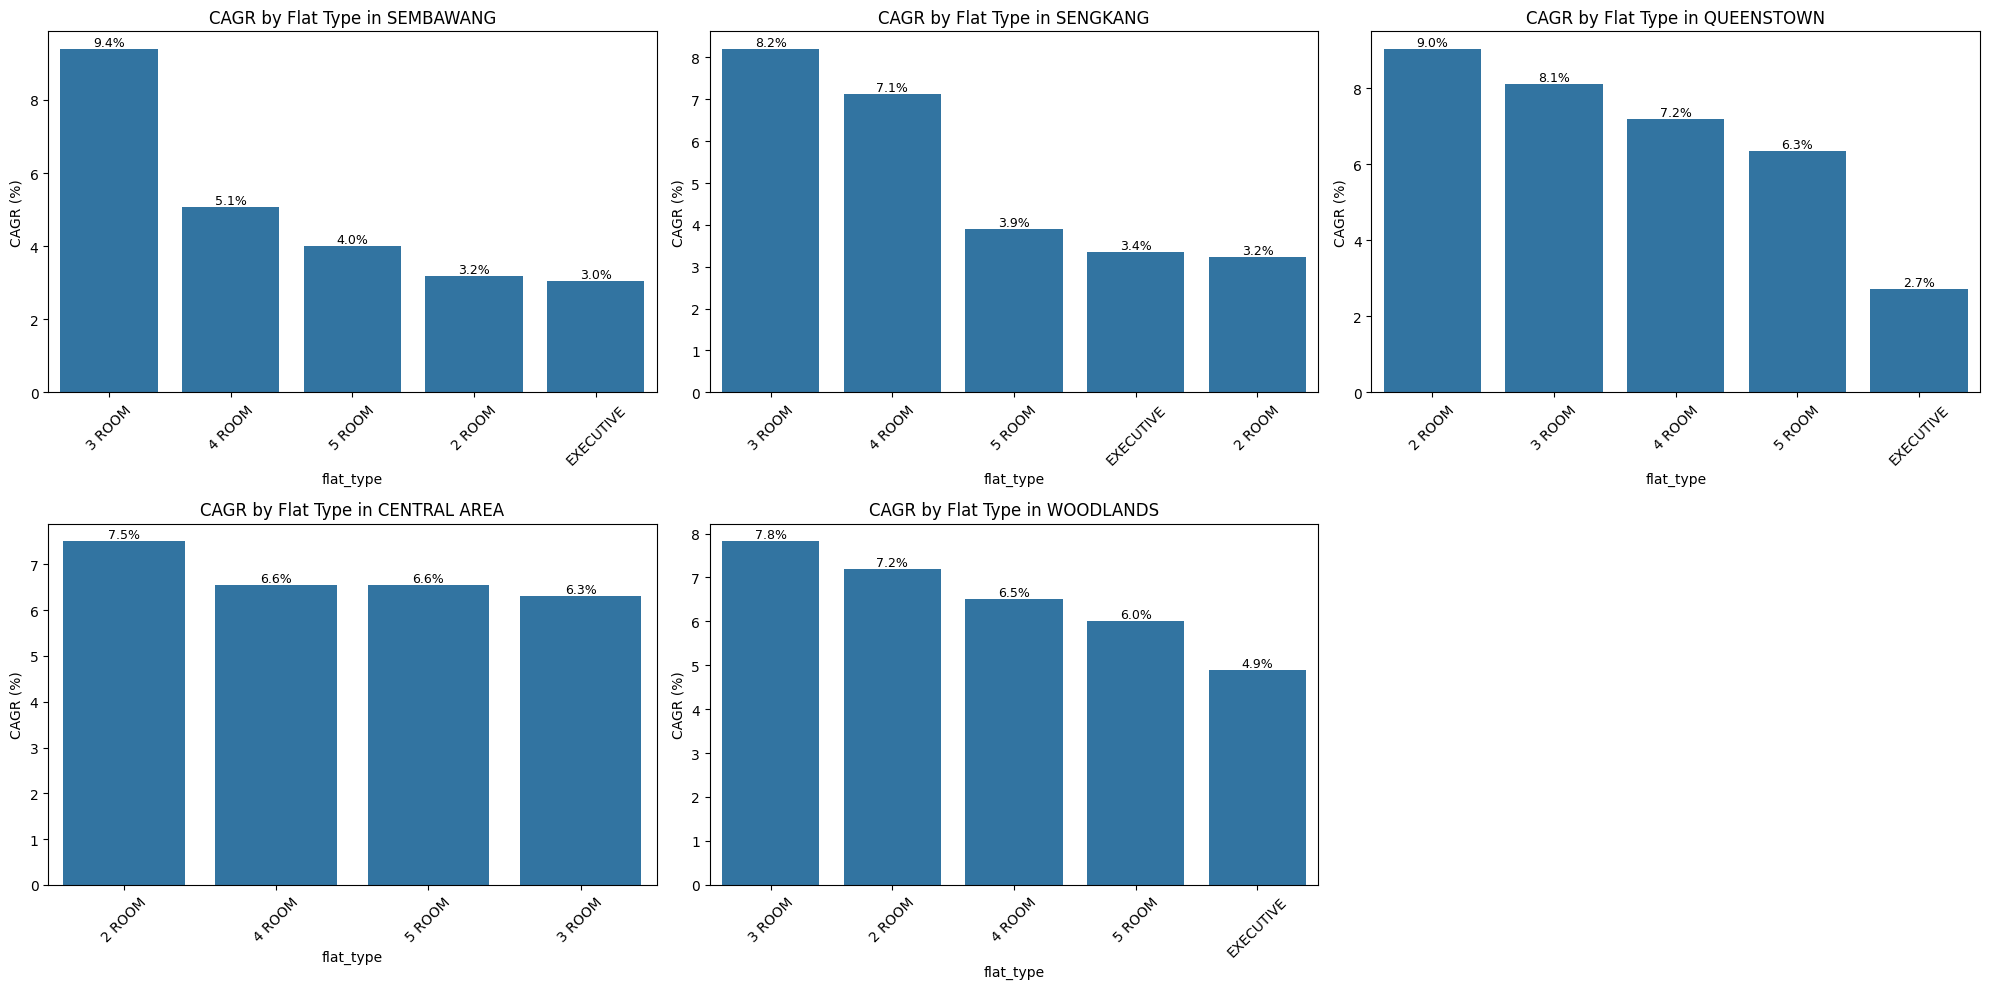

In [12]:
# 1. Analysis by Flat Type within Top Towns
# =========================================
print("\n1. ANALYSIS BY FLAT TYPE WITHIN TOP TOWNS")
print("------------------------------------------")

# Get top 5 towns
top_5_towns = top_roi_locations.head(5)['town'].tolist()

# Group data by town and flat_type for the top towns
flat_type_analysis = df_filtered[df_filtered['town'].isin(top_5_towns)].copy()
flat_type_analysis['recent'] = flat_type_analysis['year'] >= latest_year - 3  # Flag for recent transactions

# Calculate average prices, growth, and transactions by flat_type
flat_type_metrics = []

for town in top_5_towns:
    town_data = flat_type_analysis[flat_type_analysis['town'] == town]
    flat_types = town_data['flat_type'].unique()

    for flat_type in flat_types:
        flat_data = town_data[town_data['flat_type'] == flat_type]

        # Only process if we have enough data
        if len(flat_data) >= 10:
            # Calculate average price from the last 3 years
            recent_data = flat_data[flat_data['recent']]
            if len(recent_data) > 0:
                recent_avg_price = recent_data['price_per_sqm'].mean()
                recent_count = len(recent_data)
            else:
                recent_avg_price = None
                recent_count = 0

            # Calculate historical data
            historical_years = flat_data['year'].unique()
            if len(historical_years) >= 2:
                earliest_year = min(historical_years)
                latest_year = max(historical_years)

                earliest_data = flat_data[flat_data['year'] == earliest_year]
                latest_data = flat_data[flat_data['year'] == latest_year]

                earliest_price = earliest_data['price_per_sqm'].mean()
                latest_price = latest_data['price_per_sqm'].mean()

                years_diff = latest_year - earliest_year
                if years_diff > 0 and earliest_price > 0:
                    flat_cagr = (((latest_price / earliest_price) ** (1 / years_diff)) - 1) * 100
                else:
                    flat_cagr = None
            else:
                earliest_year = None
                latest_year = None
                flat_cagr = None

            # Add to metrics
            flat_type_metrics.append({
                'town': town,
                'flat_type': flat_type,
                'avg_price_per_sqm': recent_avg_price,
                'recent_transactions': recent_count,
                'earliest_year': earliest_year,
                'latest_year': latest_year,
                'cagr': flat_cagr
            })

# Convert to DataFrame and sort by town and CAGR (descending)
flat_type_df = pd.DataFrame(flat_type_metrics)
flat_type_df.sort_values(['town', 'cagr'], ascending=[True, False], inplace=True)

# Print summary of flat types by town
for town in top_5_towns:
    print(f"\nFlat Type Analysis for {town}:")
    town_flats = flat_type_df[flat_type_df['town'] == town]
    if not town_flats.empty:
        print(town_flats[['flat_type', 'avg_price_per_sqm', 'recent_transactions', 'cagr']].to_string(index=False))
    else:
        print("No sufficient data for analysis")

# Create a grid layout for the 5 towns
plt.figure(figsize=(20, 10))
for i, town in enumerate(top_5_towns):
    town_flats = flat_type_df[flat_type_df['town'] == town]
    if len(town_flats) > 0:
        plt.subplot(2, 3, i+1)  # 2 rows, 3 columns
        town_flats = town_flats.sort_values('cagr', ascending=False)
        barplot = sns.barplot(x='flat_type', y='cagr', data=town_flats)
        plt.title(f"CAGR by Flat Type in {town}", fontsize=12)
        plt.xticks(rotation=45)
        plt.ylabel('CAGR (%)')

        # Add value labels on bars
        for j, p in enumerate(barplot.patches):
            if not np.isnan(p.get_height()):
                barplot.annotate(f"{p.get_height():.1f}%",
                                (p.get_x() + p.get_width() / 2., p.get_height()),
                                ha = 'center', va = 'bottom', fontsize=9)

plt.tight_layout()
plt.show()



2. ANALYSIS BY STOREY RANGE WITHIN TOP TOWNS
--------------------------------------------


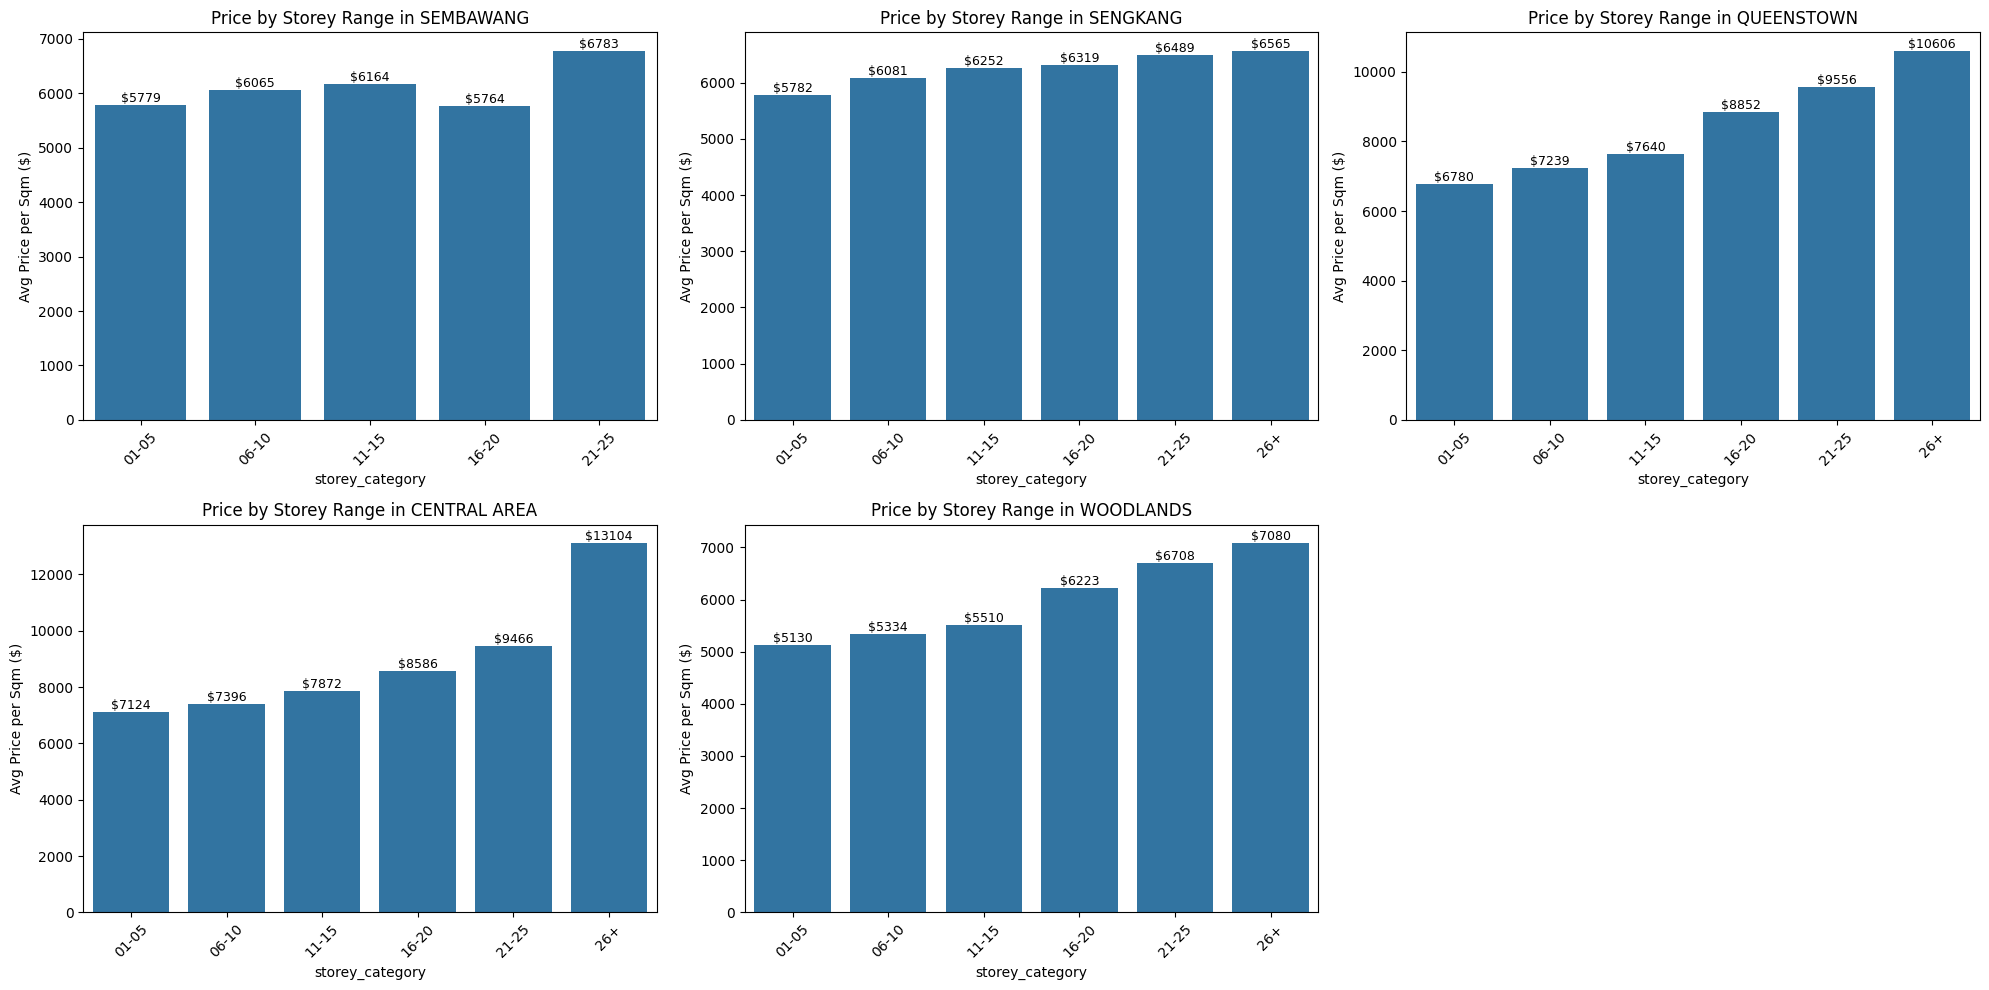

In [13]:
# 2. Analysis by Storey Range within Top Towns
# ===========================================
print("\n\n2. ANALYSIS BY STOREY RANGE WITHIN TOP TOWNS")
print("--------------------------------------------")

# Group data by town and storey_range for the top towns
storey_analysis = df_filtered[df_filtered['town'].isin(top_5_towns)].copy()

# Create a numerical representation of storey range for easier analysis
storey_analysis['storey_min'] = storey_analysis['storey_range'].str.split(' TO ', expand=True)[0].astype(int)
storey_analysis['storey_max'] = storey_analysis['storey_range'].str.split(' TO ', expand=True)[1].astype(int)
storey_analysis['storey_mid'] = (storey_analysis['storey_min'] + storey_analysis['storey_max']) / 2

# Create storey categories
storey_analysis['storey_category'] = pd.cut(
    storey_analysis['storey_mid'],
    bins=[0, 5, 10, 15, 20, 25, 50],
    labels=['01-05', '06-10', '11-15', '16-20', '21-25', '26+']
)

# Calculate average prices, growth, and transactions by storey_category
storey_metrics = []

for town in top_5_towns:
    town_data = storey_analysis[storey_analysis['town'] == town]
    storey_categories = town_data['storey_category'].unique()

    for storey_cat in storey_categories:
        storey_data = town_data[town_data['storey_category'] == storey_cat]

        # Only process if we have enough data
        if len(storey_data) >= 10:
            # Calculate recent average price (last 3 years)
            recent_data = storey_data[storey_data['year'] >= latest_year - 3]
            if len(recent_data) > 0:
                recent_avg_price = recent_data['price_per_sqm'].mean()
                recent_count = len(recent_data)
            else:
                recent_avg_price = None
                recent_count = 0

            # Add to metrics
            storey_metrics.append({
                'town': town,
                'storey_category': storey_cat,
                'avg_price_per_sqm': recent_avg_price,
                'transactions': recent_count
            })

# Convert to DataFrame
storey_df = pd.DataFrame(storey_metrics)
storey_df.sort_values(['town', 'storey_category'], ascending=[True, True], inplace=True)

# Calculate storey premium (percentage increase from lowest to highest storey)
storey_premium = []
for town in top_5_towns:
    town_storeys = storey_df[storey_df['town'] == town].sort_values('storey_category')
    if len(town_storeys) >= 2:
        lowest_price = town_storeys.iloc[0]['avg_price_per_sqm']
        highest_price = town_storeys.iloc[-1]['avg_price_per_sqm']
        if lowest_price and highest_price and lowest_price > 0:
            premium_pct = ((highest_price / lowest_price) - 1) * 100
            storey_premium.append({
                'town': town,
                'lowest_floor_price': lowest_price,
                'highest_floor_price': highest_price,
                'premium_percentage': premium_pct
            })

storey_premium_df = pd.DataFrame(storey_premium)

# Visualize storey range price trends
plt.figure(figsize=(20, 10))
for i, town in enumerate(top_5_towns):
    town_storeys = storey_df[storey_df['town'] == town]
    if len(town_storeys) > 0:
        plt.subplot(2, 3, i+1)  # 2 rows, 3 columns
        barplot = sns.barplot(x='storey_category', y='avg_price_per_sqm', data=town_storeys)
        plt.title(f"Price by Storey Range in {town}", fontsize=12)
        plt.xticks(rotation=45)
        plt.ylabel('Avg Price per Sqm ($)')

        # Add value labels on bars
        for j, p in enumerate(barplot.patches):
            if p.get_height() > 0:
                barplot.annotate(f"${int(p.get_height())}",
                              (p.get_x() + p.get_width() / 2., p.get_height()),
                              ha = 'center', va = 'bottom', fontsize=9)

plt.tight_layout()
plt.show()



3. ANALYSIS BY STREET NAME (FOR EACH TOP TOWN)
----------------------------------------------


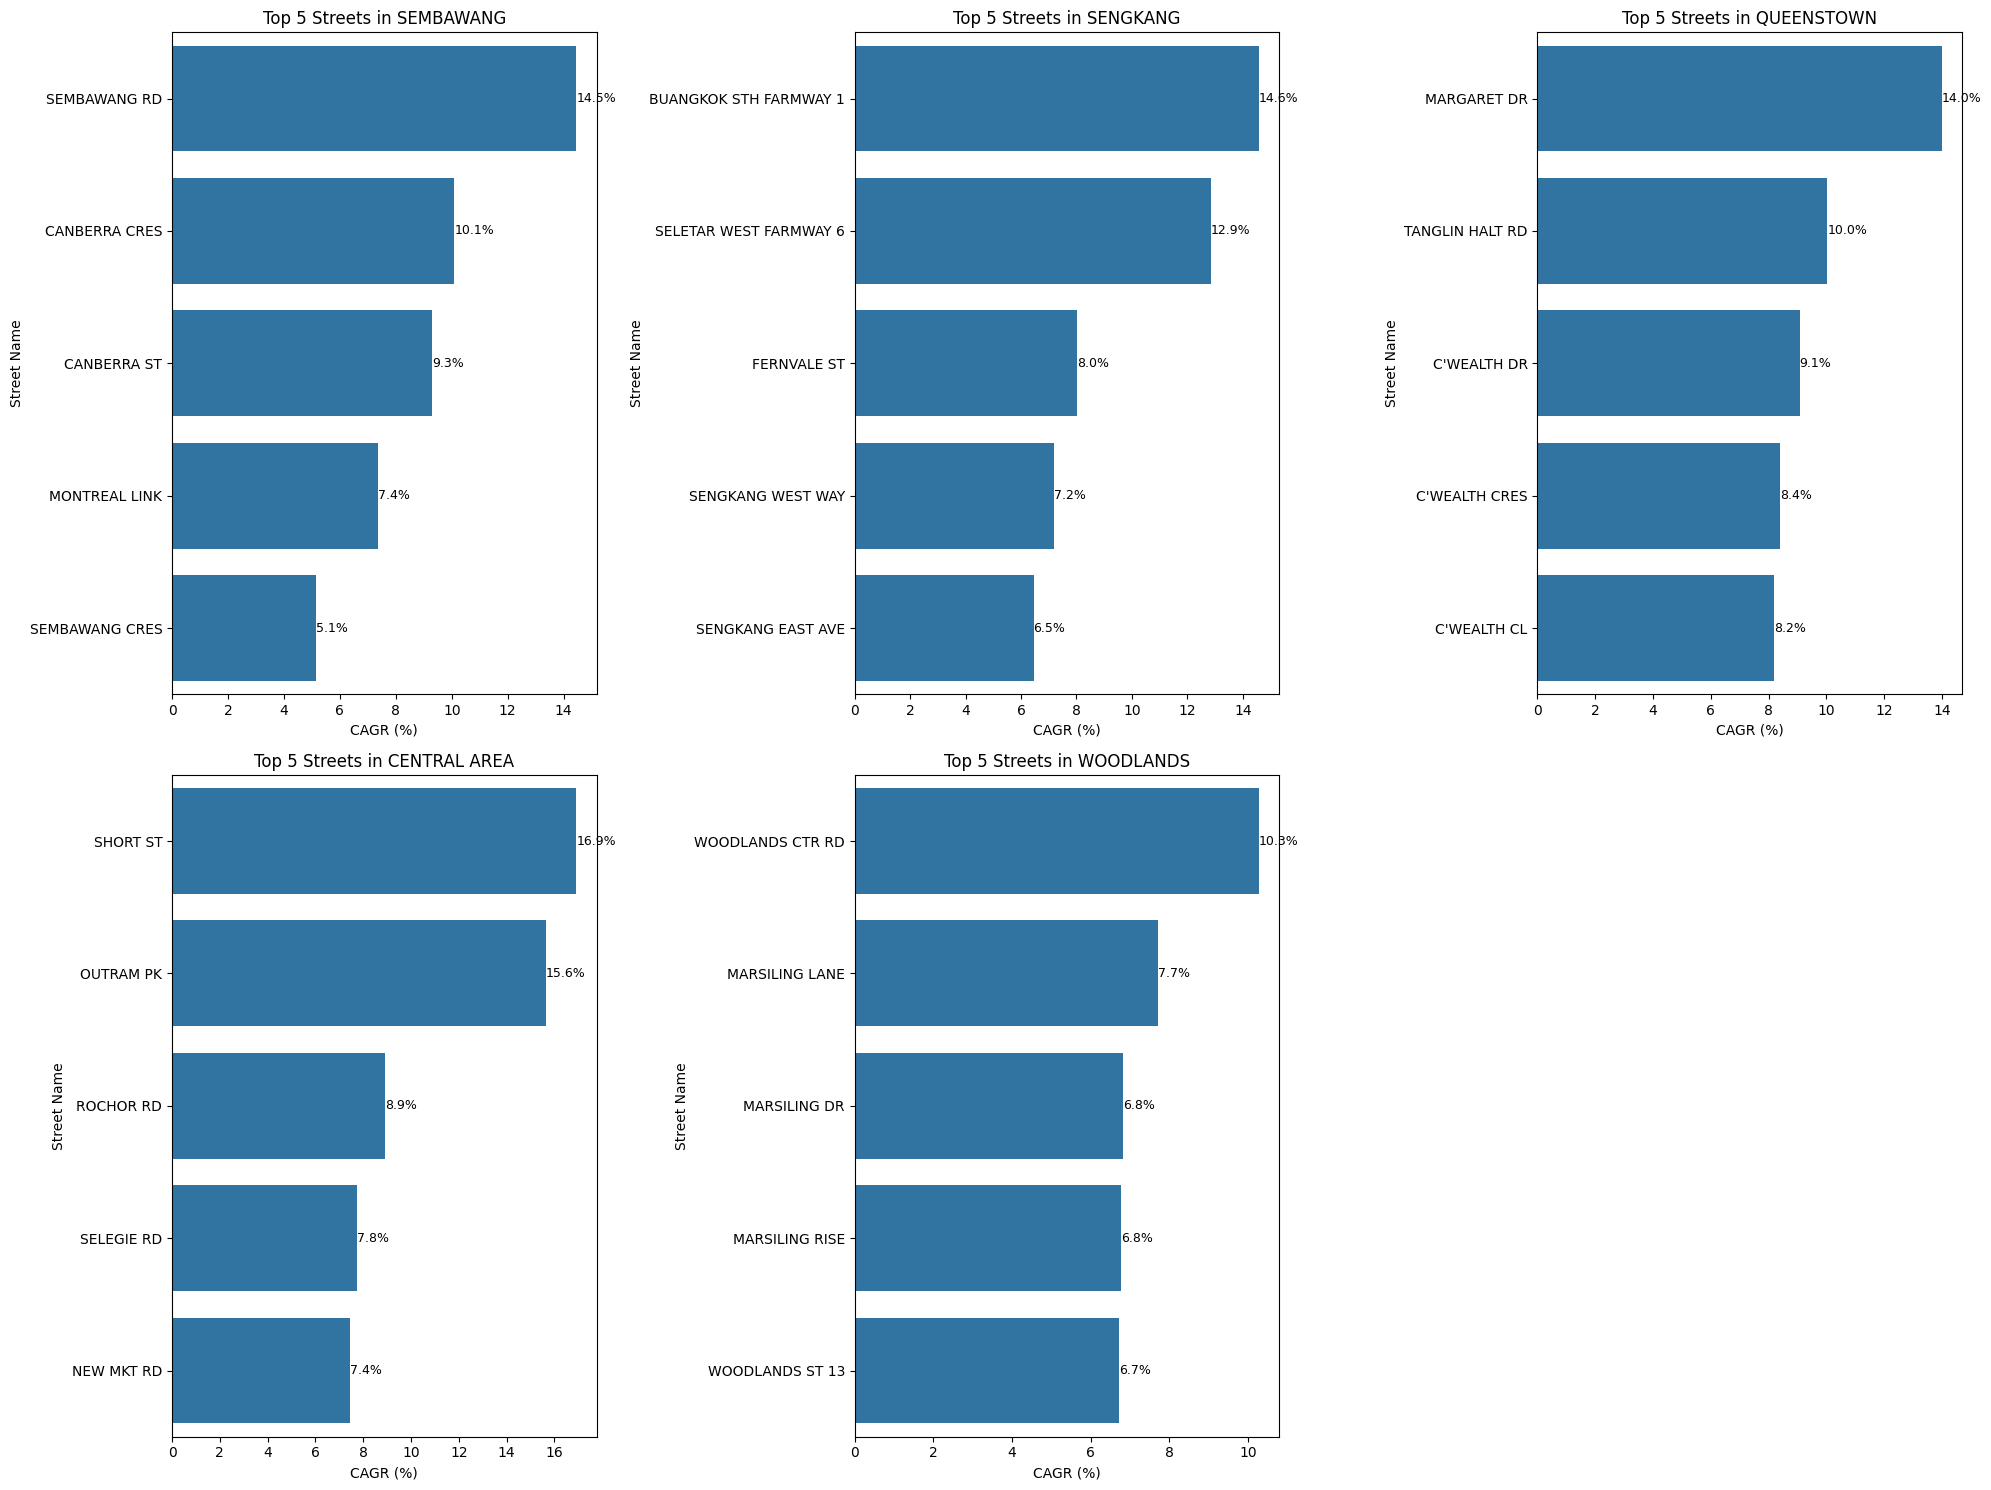

In [14]:
# 3. Analysis by Street Name (for each of the top towns)
# ====================================================
print("\n\n3. ANALYSIS BY STREET NAME (FOR EACH TOP TOWN)")
print("----------------------------------------------")

# Analyze streets for each top town
for town in top_5_towns:
    street_analysis = df_filtered[df_filtered['town'] == town].copy()
    street_analysis['recent'] = street_analysis['year'] >= latest_year - 3  # Flag for recent transactions

    # Get streets with sufficient data
    street_counts = street_analysis.groupby('street_name').size().reset_index(name='count')
    streets_with_data = street_counts[street_counts['count'] >= 10]['street_name'].tolist()

    if not streets_with_data:
        print(f"\nNo streets with sufficient data for {town}")
        continue

    # Calculate metrics for each street
    street_metrics = []

    for street in streets_with_data:
        street_data = street_analysis[street_analysis['street_name'] == street]

        # Calculate recent average price (last 3 years)
        recent_data = street_data[street_data['recent']]
        if len(recent_data) > 0:
            recent_avg_price = recent_data['price_per_sqm'].mean()
            recent_count = len(recent_data)
        else:
            recent_avg_price = None
            recent_count = 0

        # Calculate historical data if available
        historical_years = street_data['year'].unique()
        if len(historical_years) >= 2:
            earliest_year = min(historical_years)
            latest_year = max(historical_years)

            earliest_data = street_data[street_data['year'] == earliest_year]
            latest_data = street_data[street_data['year'] == latest_year]

            earliest_price = earliest_data['price_per_sqm'].mean()
            latest_price = latest_data['price_per_sqm'].mean()

            years_diff = latest_year - earliest_year
            if years_diff > 0 and earliest_price > 0:
                street_cagr = (((latest_price / earliest_price) ** (1 / years_diff)) - 1) * 100
            else:
                street_cagr = None
        else:
            earliest_year = None
            latest_year = None
            street_cagr = None

        # Add to metrics
        street_metrics.append({
            'town': town,
            'street_name': street,
            'avg_price_per_sqm': recent_avg_price,
            'recent_transactions': recent_count,
            'earliest_year': earliest_year,
            'latest_year': latest_year,
            'cagr': street_cagr
        })

    # Convert to DataFrame and sort by CAGR (descending)
    street_df = pd.DataFrame(street_metrics)
    street_df.sort_values('cagr', ascending=False, inplace=True)

# Create a combined visualization of top streets for each town
plt.figure(figsize=(20, 15))
for i, town in enumerate(top_5_towns):
    street_analysis = df_filtered[df_filtered['town'] == town].copy()
    street_analysis['recent'] = street_analysis['year'] >= latest_year - 3

    # Get streets with sufficient data
    street_counts = street_analysis.groupby('street_name').size().reset_index(name='count')
    streets_with_data = street_counts[street_counts['count'] >= 10]['street_name'].tolist()

    if not streets_with_data:
        continue

    # Calculate metrics for each street
    street_metrics = []
    for street in streets_with_data:
        street_data = street_analysis[street_analysis['street_name'] == street]
        historical_years = street_data['year'].unique()
        if len(historical_years) >= 2:
            earliest_year = min(historical_years)
            latest_year = max(historical_years)
            earliest_data = street_data[street_data['year'] == earliest_year]
            latest_data = street_data[street_data['year'] == latest_year]
            earliest_price = earliest_data['price_per_sqm'].mean()
            latest_price = latest_data['price_per_sqm'].mean()
            years_diff = latest_year - earliest_year
            if years_diff > 0 and earliest_price > 0:
                street_cagr = (((latest_price / earliest_price) ** (1 / years_diff)) - 1) * 100
                street_metrics.append({
                    'street_name': street,
                    'cagr': street_cagr
                })

    if not street_metrics:
        continue

    street_df = pd.DataFrame(street_metrics)
    street_df.sort_values('cagr', ascending=False, inplace=True)
    top_streets = street_df.head(5)

    plt.subplot(2, 3, i+1)
    barplot = sns.barplot(x='cagr', y='street_name', data=top_streets)
    plt.title(f"Top 5 Streets in {town}", fontsize=12)
    plt.xlabel('CAGR (%)')
    plt.ylabel('Street Name')

    # Add value labels
    for j, p in enumerate(barplot.patches):
        barplot.annotate(f"{p.get_width():.1f}%",
                     (p.get_width(), p.get_y() + p.get_height() / 2),
                     ha = 'left', va = 'center', fontsize=9)

plt.tight_layout()
plt.show()


Top 10 Town-Flat Type-Storey Range Combinations by ROI Score (Descending):
        town flat_type storey_category     cagr  sharpe_ratio  lease_factor  roi_score
   SEMBAWANG    3 ROOM           01-05 9.401426      0.470135      0.830357   9.597162
   SEMBAWANG    3 ROOM           11-15 9.143860      0.514732      0.860000   9.580167
   SEMBAWANG    3 ROOM           06-10 9.360894      0.407937      0.825226   9.431562
CENTRAL AREA    4 ROOM             26+ 9.136227      0.390588      0.683594   8.885519
   SEMBAWANG    3 ROOM           16-20 7.620688      0.634180      0.849432   8.726422
   WOODLANDS    4 ROOM             26+ 7.542628      0.593236      0.845588   8.580283
CENTRAL AREA    5 ROOM           01-05 8.897238      0.297716      0.668679   8.495197
    SENGKANG    3 ROOM           01-05 8.100593      0.345877      0.713055   8.144807
   WOODLANDS    4 ROOM           16-20 8.007400      0.364477      0.717150   8.127009
  QUEENSTOWN    2 ROOM           16-20 9.015095      0

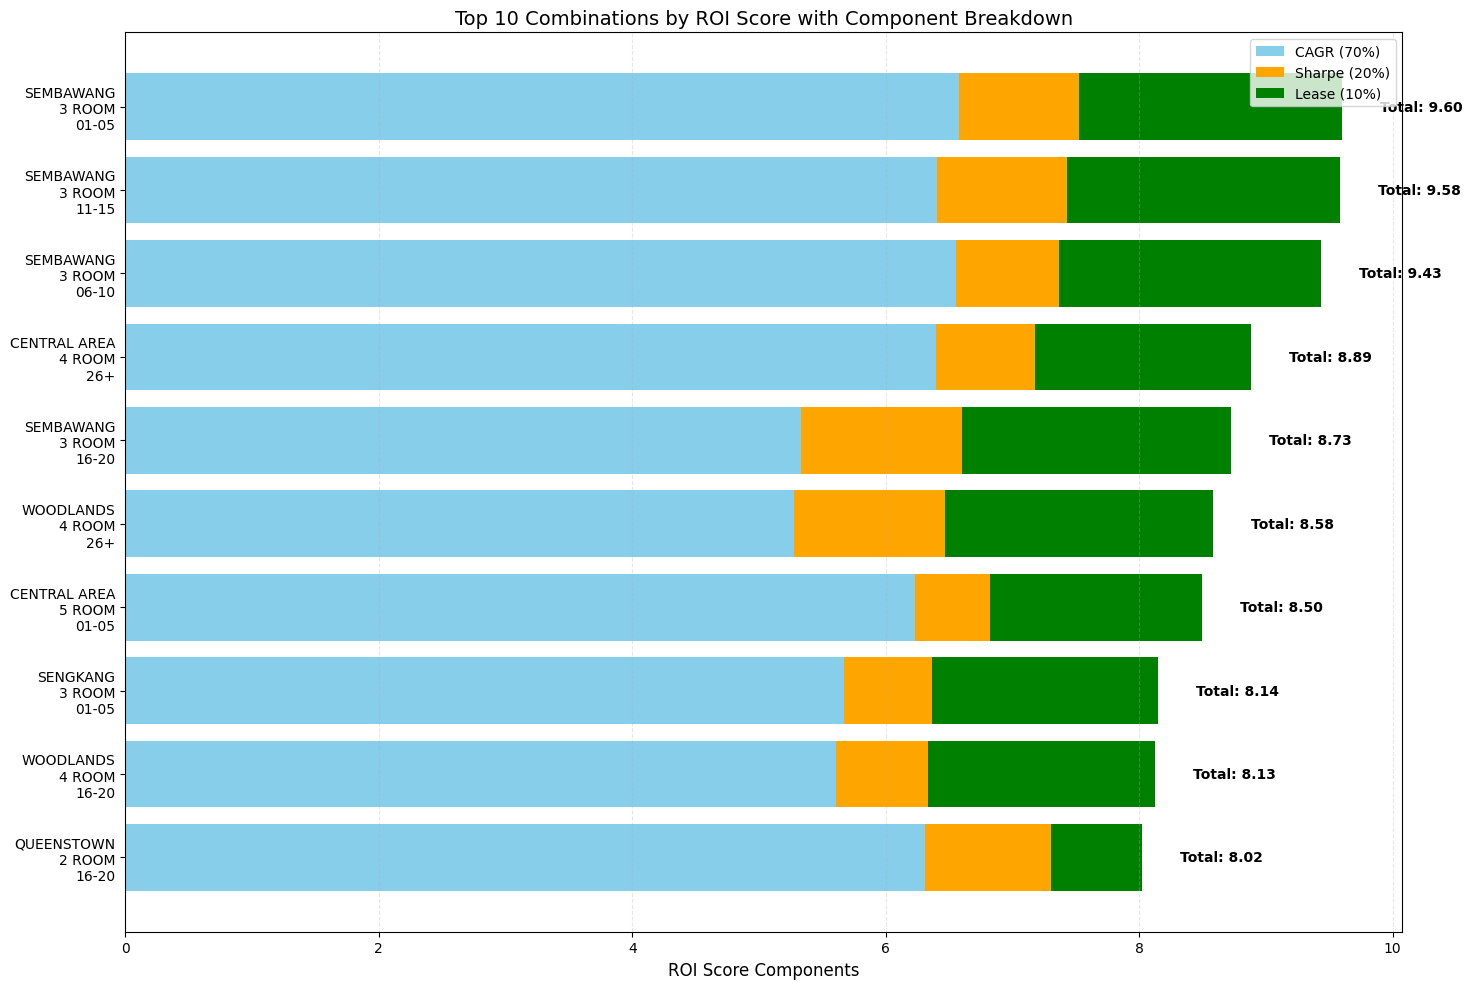


Additional information on Top 10 ROI Combinations:
        Town Flat Type Storey Range  Avg Price/SQM  Recent Transactions  Avg Remaining Lease
   SEMBAWANG    3 ROOM        01-05    6666.155307                  103            88.142857
   SEMBAWANG    3 ROOM        11-15    6909.089048                  109            90.040000
   SEMBAWANG    3 ROOM        06-10    6863.023869                   77            87.814433
CENTRAL AREA    4 ROOM          26+   13391.418422                   65            78.750000
   SEMBAWANG    3 ROOM        16-20    6680.933567                    6            89.363636
   WOODLANDS    4 ROOM          26+    6934.463527                   19            89.117647
CENTRAL AREA    5 ROOM        01-05    6900.676410                    5            77.795455
    SENGKANG    3 ROOM        01-05    6552.987200                  147            80.635514
   WOODLANDS    4 ROOM        16-20    6224.643234                   56            80.897590
  QUEENSTOWN    2 

In [15]:
# Create a combined analysis to find the best performing combinations
combined_analysis = df_filtered[df_filtered['town'].isin(top_5_towns)].copy()
combined_analysis['recent'] = combined_analysis['year'] >= latest_year - 3

# Create storey categories
combined_analysis['storey_min'] = combined_analysis['storey_range'].str.split(' TO ', expand=True)[0].astype(int)
combined_analysis['storey_max'] = combined_analysis['storey_range'].str.split(' TO ', expand=True)[1].astype(int)
combined_analysis['storey_mid'] = (combined_analysis['storey_min'] + combined_analysis['storey_max']) / 2
combined_analysis['storey_category'] = pd.cut(
    combined_analysis['storey_mid'],
    bins=[0, 5, 10, 15, 20, 25, 50],
    labels=['01-05', '06-10', '11-15', '16-20', '21-25', '26+']
)

# Create combination level groups for analysis
combo_metrics = []

# Group by town, flat_type, and storey_category
for town in top_5_towns:
    town_data = combined_analysis[combined_analysis['town'] == town]

    flat_types = town_data['flat_type'].unique()
    for flat_type in flat_types:
        flat_data = town_data[town_data['flat_type'] == flat_type]

        storey_cats = flat_data['storey_category'].dropna().unique()
        for storey_cat in storey_cats:
            combo_data = flat_data[flat_data['storey_category'] == storey_cat]

            # Only process if we have enough data
            if len(combo_data) >= 15:
                # Calculate recent average price (last 3 years)
                recent_data = combo_data[combo_data['recent']]
                if len(recent_data) > 0:
                    recent_avg_price = recent_data['price_per_sqm'].mean()
                    recent_count = len(recent_data)
                else:
                    recent_avg_price = None
                    recent_count = 0

                # Calculate historical data for CAGR and Sharpe ratio
                years = combo_data['year'].unique()
                if len(years) >= 5:  # Need at least 5 years for meaningful trend analysis
                    # Calculate year-over-year price changes for each year
                    yearly_prices = combo_data.groupby('year')['price_per_sqm'].mean().reset_index()
                    yearly_prices = yearly_prices.sort_values('year')

                    # Calculate CAGR
                    earliest_year = min(years)
                    latest_year = max(years)
                    earliest_price = yearly_prices[yearly_prices['year'] == earliest_year]['price_per_sqm'].values[0]
                    latest_price = yearly_prices[yearly_prices['year'] == latest_year]['price_per_sqm'].values[0]
                    years_diff = latest_year - earliest_year

                    if years_diff > 0 and earliest_price > 0:
                        combo_cagr = (((latest_price / earliest_price) ** (1 / years_diff)) - 1) * 100

                        # Calculate YoY appreciation for Sharpe ratio
                        yearly_prices['prev_price'] = yearly_prices['price_per_sqm'].shift(1)
                        yearly_prices['yoy_return'] = (yearly_prices['price_per_sqm'] - yearly_prices['prev_price']) / yearly_prices['prev_price'] * 100

                        # Calculate volatility
                        volatility = yearly_prices['yoy_return'].std()
                        avg_return = yearly_prices['yoy_return'].mean()

                        # Calculate Sharpe ratio
                        if volatility > 0:
                            sharpe_ratio = (avg_return - risk_free_rate) / volatility
                        else:
                            sharpe_ratio = 0

                        # Calculate average remaining lease
                        avg_remaining_lease = combo_data['remaining_lease'].mean()

                        # Calculate lease factor
                        predicted_lease_factor = (avg_remaining_lease - config['min_acceptable_lease']) / (config['max_lease'] - config['min_acceptable_lease'])
                        predicted_lease_factor = min(max(predicted_lease_factor, 0), 1)  # Clip between 0 and 1

                        # Calculate predicted ROI score using the same formula
                        predicted_roi_score = (
                            config['cagr_weight'] * combo_cagr +
                            config['sharpe_weight'] * sharpe_ratio * config['sharpe_scaling_factor'] +
                            config['lease_weight'] * predicted_lease_factor * config['lease_scaling_factor']
                        )

                        combo_metrics.append({
                            'town': town,
                            'flat_type': flat_type,
                            'storey_category': storey_cat,
                            'avg_price_per_sqm': recent_avg_price,
                            'transactions': recent_count,
                            'cagr': combo_cagr,
                            'sharpe_ratio': sharpe_ratio,
                            'lease_factor': predicted_lease_factor,
                            'roi_score': predicted_roi_score,
                            'avg_remaining_lease': avg_remaining_lease
                        })

# Convert to DataFrame and sort by ROI score (descending)
if combo_metrics:
    combo_df = pd.DataFrame(combo_metrics)
    top_combos = combo_df.sort_values('roi_score', ascending=False).head(10).reset_index(drop=True)
    top_combos = top_combos.iloc[::-1].reset_index(drop=True)  # Reverse for top-to-bottom plotting

    # Print top combinations by ROI score (from highest to lowest)
    print("\nTop 10 Town-Flat Type-Storey Range Combinations by ROI Score (Descending):")
    print(top_combos.iloc[::-1][['town', 'flat_type', 'storey_category', 'cagr', 'sharpe_ratio', 'lease_factor', 'roi_score']].to_string(index=False))

    # Calculate component contributions for visualization
    top_combos['cagr_contribution'] = config['cagr_weight'] * top_combos['cagr']
    top_combos['sharpe_contribution'] = config['sharpe_weight'] * top_combos['sharpe_ratio'] * config['sharpe_scaling_factor']
    top_combos['lease_contribution'] = config['lease_weight'] * top_combos['lease_factor'] * config['lease_scaling_factor']

    # Create simple horizontal bar chart for ROI components
    plt.figure(figsize=(18, 10))

    # Set up the positions for the bars
    pos = list(range(len(top_combos)))
    width = 0.8

    # Get the data
    towns = top_combos['town'].tolist()
    flat_types = top_combos['flat_type'].tolist()
    storey_cats = top_combos['storey_category'].tolist()
    combos = [f"{town}\n{flat_type}\n{storey}" for town, flat_type, storey in zip(towns, flat_types, storey_cats)]

    # Create the stacked bar chart
    p1 = plt.barh([p for p in pos],
                 top_combos['cagr_contribution'].tolist(),
                 width,
                 color='skyblue',
                 label='CAGR (70%)')

    p2 = plt.barh([p for p in pos],
                 top_combos['sharpe_contribution'].tolist(),
                 width,
                 left=top_combos['cagr_contribution'].tolist(),
                 color='orange',
                 label='Sharpe (20%)')

    p3 = plt.barh([p for p in pos],
                 top_combos['lease_contribution'].tolist(),
                 width,
                 left=[i+j for i,j in zip(top_combos['cagr_contribution'].tolist(),
                                          top_combos['sharpe_contribution'].tolist())],
                 color='green',
                 label='Lease (10%)')

    # Customize the chart
    plt.yticks(pos, combos, fontsize=10)
    plt.xlabel('ROI Score Components', fontsize=12)
    plt.title('Top 10 Combinations by ROI Score with Component Breakdown', fontsize=14)
    plt.legend(loc='upper right')

    # Add gridlines
    plt.grid(axis='x', linestyle='--', alpha=0.3)

    # Add total ROI scores
    for i, roi in enumerate(top_combos['roi_score']):
        plt.text(roi + 0.3, i, f'Total: {roi:.2f}', va='center', ha='left', fontweight='bold')

    # Adjust layout
    plt.tight_layout()
    plt.subplots_adjust(left=0.25) # Add more space for labels
    plt.show()

if combo_metrics:
    print("\nAdditional information on Top 10 ROI Combinations:")
    value_data = top_combos[['town', 'flat_type', 'storey_category', 'avg_price_per_sqm', 'transactions', 'avg_remaining_lease']]
    value_data.columns = ['Town', 'Flat Type', 'Storey Range', 'Avg Price/SQM', 'Recent Transactions', 'Avg Remaining Lease']
    print(value_data.iloc[::-1].to_string(index=False))
else:
    print("Insufficient data for combination ROI analysis.")

# Descriptive Analysis — Key Findings

## Top 5 Towns by Historical ROI Score

Using a weighted composite of CAGR (70%), rolling Sharpe ratio (20%), and remaining lease factor (10%), the five towns with the strongest historical risk-adjusted returns are:

1. **Sembawang** — high CAGR driven by a lower price base and consistent appreciation over the past decade.
2. **Sengkang** — strong, steady growth with relatively low volatility, supported by long remaining leases (85+ years on average).
3. **Queenstown** — mature estate with premium pricing but sustained appreciation, benefiting from central location.
4. **Central Area** — highest absolute prices per sqm but solid growth rates, particularly for higher-floor units.
5. **Woodlands** — affordable entry point with above-average CAGR, though higher volatility than the other four.

## Drill-Down Insights

- **Flat type matters**: Within the top towns, 3-room and 4-room flats generally show the highest CAGR, balancing demand breadth with price appreciation. Executive flats tend to underperform on a per-sqm basis due to larger floor areas diluting per-sqm growth.
- **Storey premium is real but varies**: Higher floors consistently command a price premium (typically 15–30% from lowest to highest storey range), but the premium is most pronounced in towns with taller blocks (Sengkang, Central Area).
- **Street-level variation is significant**: Even within the same town, CAGR can differ by several percentage points between streets — location within a town matters, not just the town itself.

## Combined ROI Ranking

The stacked ROI component chart shows that **CAGR is the dominant driver** of the composite score across all top combinations, with the Sharpe ratio acting as a meaningful differentiator between similarly-growing towns and the lease factor providing a small but consistent boost to newer estates.

## What This Means

The descriptive analysis identifies *where* to look — the towns, flat types, and storey ranges with the strongest historical track record. However, past performance alone is insufficient for an investment decision. The next notebook (`02_arima_forecasting.ipynb`) takes these top-performing combinations and asks: **will the trend continue?** — using ARIMA time series forecasting and Monte Carlo simulation to project prices 10 years forward with uncertainty bounds.

In [16]:
# ============================================================================
# EXPORT DATA FOR ARIMA FORECASTING NOTEBOOK
# ============================================================================

import pickle

os.makedirs('checkpoints', exist_ok=True)

# Save processed data for the forecasting notebook
export_data = {
    'df_filtered': df_filtered,
    'top_5_towns': top_5_towns,
    'top_roi_locations': top_roi_locations,
    'appreciation_df': appreciation_df,
    'town_year_prices': town_year_prices
}

with open('checkpoints/descriptive_analysis_output.pkl', 'wb') as f:
    pickle.dump(export_data, f)

print('Exported data to checkpoints/descriptive_analysis_output.pkl')
print(f'  - df_filtered: {df_filtered.shape}')
print(f'  - top_5_towns: {top_5_towns}')
print(f'  - top_roi_locations: {top_roi_locations.shape}')
print(f'  - appreciation_df: {appreciation_df.shape}')
print(f'  - town_year_prices: {town_year_prices.shape}')

Exported data to checkpoints/descriptive_analysis_output.pkl
  - df_filtered: (947306, 15)
  - top_5_towns: ['SEMBAWANG', 'SENGKANG', 'QUEENSTOWN', 'CENTRAL AREA', 'WOODLANDS']
  - top_roi_locations: (26, 12)
  - appreciation_df: (26, 12)
  - town_year_prices: (915, 3)
